#scalar autograd from- cratch - Deep Learning 


## Part 1: Discrete Distribution Sampler
Implementation of a custom sampler with the following constraints:
* **Validation:** Ensures `dist` is a valid probability distribution.
* **Efficiency:** Uses a CDF-based approach with a single `for` loop.
* **Autograd:** Logic is wrapped in `torch.no_grad()` to return a Leaf Tensor, as required.

--- Verification ---
Sample [0.5, 0.5]: tensor([0., 1., 1., 0., 0., 0., 1., 0., 0., 1.])

Tensor A:
 tensor([[2., 2., 1., 2., 0., 2., 2., 2.],
        [2., 2., 2., 1., 2., 2., 2., 2.]], requires_grad=True)

A.requires_grad: True | A.grad: None

--- Plotting Histogram ---


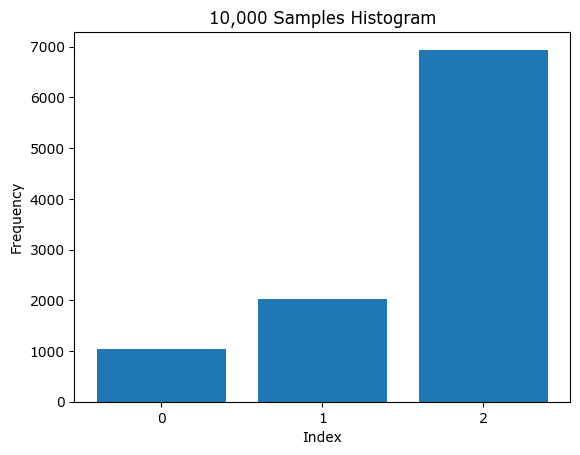

In [1]:
import torch
import matplotlib.pyplot as plt

def my_sampler(size, dist, requires_grad=False):
    # Standardize input as a float tensor
    dist = torch.tensor(dist, dtype=torch.float32)
    
    # Ensure valid probability distribution (positive values summing to 1)
    if not torch.all(dist >= 0) or not torch.isclose(torch.sum(dist), torch.tensor(1.0)):
        raise ValueError("Invalid probability distribution.")

    # Generate samples without tracking internal graph operations
    with torch.no_grad():
        random_vals = torch.rand(size)
        samples = torch.zeros(size)
        
        cdf = 0.0
        # Iterate through the distribution to find the correct index for each sample
        for i in range(len(dist) - 1):
            cdf += dist[i]
            samples[random_vals > cdf] += 1

    # Return as a leaf tensor with grad tracking if enabled
    if requires_grad:
        samples.requires_grad_(True)
    return samples

# --- Verification & Plotting ---
print("--- Verification ---")
print("Sample [0.5, 0.5]:", my_sampler(10, [0.5, 0.5]))

A = my_sampler((2, 8), [0.1, 0.2, 0.7], requires_grad=True)
print("\nTensor A:\n", A)
print(f"\nA.requires_grad: {A.requires_grad} | A.grad: {A.grad}")

# Visualize 10,000 samples from [0.1, 0.2, 0.7]
print("\n--- Plotting Histogram ---")
samples_10k = my_sampler(10000, [0.1, 0.2, 0.7])

plt.hist(samples_10k.numpy(), bins=[-0.5, 0.5, 1.5, 2.5], rwidth=0.8, align='mid')
plt.xticks([0, 1, 2])
plt.xlabel('Index')
plt.ylabel('Frequency')
plt.title('10,000 Samples Histogram')
plt.show()

## Part 2: Manual Autograd Engine
A simplified scalar autograd system based on a computational graph and the chain rule.

In [2]:
import math
import torch

class MyScalar:
    def __init__(self, val, immediate_derivative=1.0, parent=None):
        self.val = val
        self.immediate_derivative = immediate_derivative
        self.parent = parent

# Math operations with corresponding local derivatives
def exp(a): 
    return MyScalar(math.exp(a.val), immediate_derivative=math.exp(a.val), parent=a)

def ln(a): 
    return MyScalar(math.log(a.val), immediate_derivative=1.0 / a.val, parent=a)

def sin(a): 
    return MyScalar(math.sin(a.val), immediate_derivative=math.cos(a.val), parent=a)

def cos(a): 
    return MyScalar(math.cos(a.val), immediate_derivative=-math.sin(a.val), parent=a)

def power(a, n): 
    return MyScalar(math.pow(a.val, n), immediate_derivative=n * math.pow(a.val, n - 1), parent=a)

def mul(a, n): 
    return MyScalar(a.val * n, immediate_derivative=n, parent=a)

def add(a, n): 
    return MyScalar(a.val + n, immediate_derivative=1.0, parent=a)

def get_gradient(target):
    """ Computes gradients for all dependencies using the chain rule recursively. """
    grads = {}

    def compute(node, current_grad):
        # Accumulate gradients for each node found in the graph
        grads[node] = grads.get(node, 0.0) + current_grad
        
        # Propagate backward if a parent exists
        if node.parent is not None:
            compute(node.parent, current_grad * node.immediate_derivative)

    # Begin backprop from the target scalar
    compute(target, 1.0)
    return grads

# --- Comparison with PyTorch ---
a_val = 2.0
a = MyScalar(a_val)
c = exp(power(a, 2)) # e^(a^2)
custom_res = get_gradient(c)[a]

# Reference PyTorch implementation
a_torch = torch.tensor(a_val, requires_grad=True)
c_torch = torch.exp(a_torch**2)
c_torch.backward()
torch_res = a_torch.grad.item()

print(f"Custom dc/da: {custom_res:.4f}")
print(f"PyTorch dc/da: {torch_res:.4f}")
print(f"Match: {math.isclose(custom_res, torch_res, rel_tol=1e-5)}")

Custom dc/da: 218.3926
PyTorch dc/da: 218.3926
Match: True
